cleaning up all over again

In [1]:
cd /Users/ibehbehani/csm_pipeline

/Users/ibehbehani/csm_pipeline


In [2]:
from conv_reproj import match
from align_and_diff import a_d
from header_setup import read

from matplotlib import pyplot as plt
import numpy as np

from astropy.io import fits
from pm import pm_correct
from astropy import units as u
from astropy.wcs import WCS
import cmasher as cmr

from astropy.time import Time
from astropy.coordinates import SkyCoord

Match function imported.
running


In [3]:
import interp_and_iat_2d

hello again


In [4]:
from everything import full_analysis
from everything import plot_1d, plot_2d
from radial import radial_read
from dens import density_model

Ready to go!


In [5]:
import os

In [6]:
cd

/Users/ibehbehani


In [7]:
hr = 'Documents/research/from_server/Betelgeuse_TE_cont_R0.image.image.tt0.fits'
lr = 'Documents/research/from_server/Betelgeuse_all_cont_1-1.image.image.tt0.fits'

In [8]:
# hr = 'Documents/cuny_ms/jan29_data/from_server/Betelgeuse_TE_cont_R0.image.image.tt0.fits'
# lr = 'Documents/cuny_ms/jan29_data/from_server/Betelgeuse_all_cont_1-1.image.image.tt0.fits'


data3, data_1d3, radius3, data_dens_1d3, data_dens_2d3, data_plot3, info3 = full_analysis(hr,lr)
# this should be lr
info3['lr']['kspatres']
# this should be hr


False
First epoch shifted to second.
Header information imported.
Header information imported.


indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in parameterized keywords must not have leading zeroes. [astropy.wcs.wcs]
indices in param

(array([499]), array([499]))
Alignment and subtraction complete. Info dictionaries imported.


/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/astropy/units/quantity.py:676: RuntimeWarning: divide by zero encountered in power
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/opt/anaconda3/envs/myenv/lib/python3.14/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/myenv/lib/py

np.float64(0.040566339161841755)

In [9]:
color = ['C6','C0','C2','black']

In [10]:
def plot_1d_bkg(data_1d,data_dens_1d,info,radius,ax1_ymin=1e-2,ax2_ymin=1e-3, ax1_ymax=1e4,ax2_ymax=1e3,xmin=0,xmax=0.45, suptitle = "1D Radial Intensity and Density Plots using original dimension data"):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''


    fig, (ax1, ax2) = plt.subplots(2, 1, figsize = [8,11])
    fig.suptitle(suptitle, size= '25')

    title = ['hr','lr','reproj','csm', 'hr_dens','lr_dens', 'reproj_dens','csm_dens']
    labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
             '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
            'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
            "CSM"]    
    
    plt.rcParams['font.sans-serif'] = ['Helvetica Neue']
    c=0
    j=0
    for j in range(len(title)):
        if j==4:
            c=0
        
        if j<4:
            ax1.plot(radius[title[c]]['arc_1d'],data_1d[title[c]].value,'o-',alpha=0.4, label = labels[c], c = color[c])
            ax1.errorbar(radius[title[c]]['arc_1d'],data_1d[title[c]].value,yerr=info[title[c]]['error'].value, c = color[c],alpha= .17)
        else:
            info[title[c]]['error_dens'] = density_model(info[title[c]]['error'],radius[title[c]]['pc_1d'])

            ax2.plot(radius[title[c]]['arc_1d'],data_dens_1d[title[c]].value,'o-',alpha=0.4,label = labels[c], c = color[c])
            ax2.errorbar(radius[title[c]]['arc_1d'],data_dens_1d[title[c]].value,yerr=info[title[c]]['error_dens'].value, c = color[c], alpha=.17)
    
        c+=1

    ax2.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
    # ax2.set_xlim(xmin,xmax)
    ax1.set_xlim(0,0.45)
    ax1.set_ylim(ax1_ymin, ax1_ymax)
    # ax2.set_ylim(ax2_ymin, ax2_ymax)

    ax1.semilogy()
    
    ax1.yaxis.set_ticks_position('both')
    ax2.yaxis.set_ticks_position('both')
    ax1.xaxis.set_ticks_position('both')
    ax2.xaxis.set_ticks_position('both')

    ax2.semilogy()

    ax1.tick_params(direction = 'in')
    ax2.tick_params(direction = 'in')


    ax1.set_title("Radial Intensity",size=18)
    ax2.set_title("Radial Density",size=18)
    ax1.set_xlabel('Radius (arc)',size=15)
    ax2.set_xlabel('Radius (arc)',size=15)
    ax1.set_ylabel(r'Intensity (Jy arc$^{-2}$)',size=15)
    ax2.set_ylabel(r'Density (g cm$^{-2}$)',size=15)
   

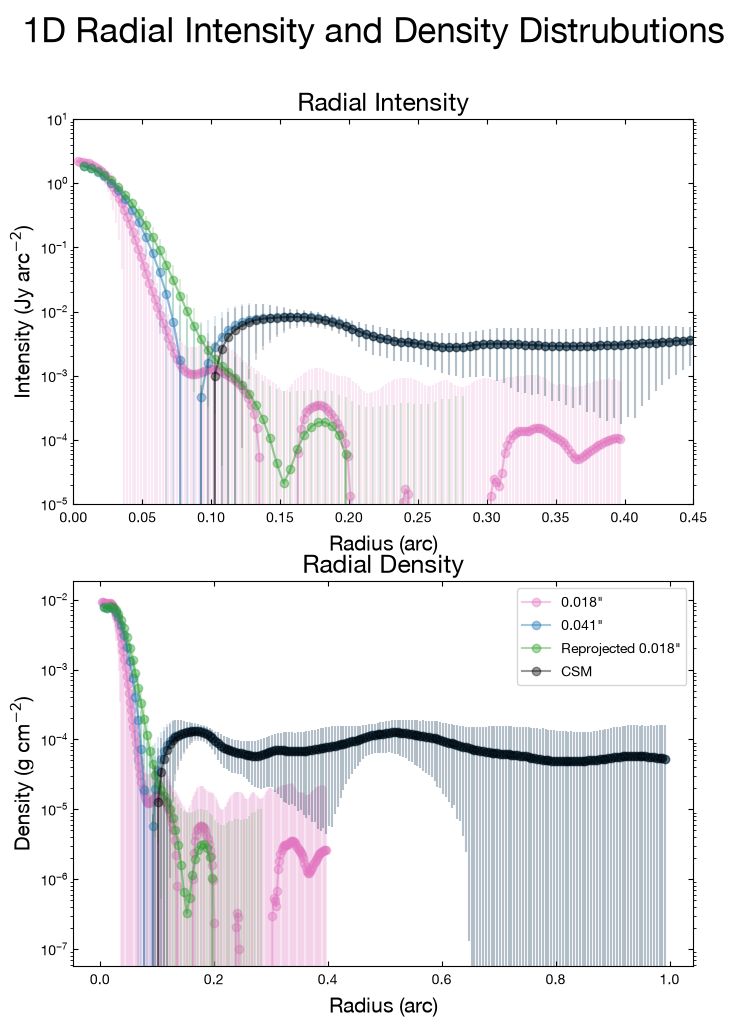

In [11]:
plot_1d_bkg(data_1d3, data_dens_1d3,info3,radius3,ax1_ymin=1e-5,ax1_ymax=1e1,ax2_ymin=1e-7,ax2_ymax=1e-1, 
        suptitle = "1D Radial Intensity and Density Distrubutions")#,xmax=0.35)
#plt.savefig('thesis/medhigh/1d_radial_all_MH.png')

#plot_1d(data_1d3, data_dens_1d3,info3,radius3,ax1_ymin=-1e-1,ax1_ymax=6e5,ax2_ymin=1e0,ax2_ymax=1e1)#,xmax=0.35)

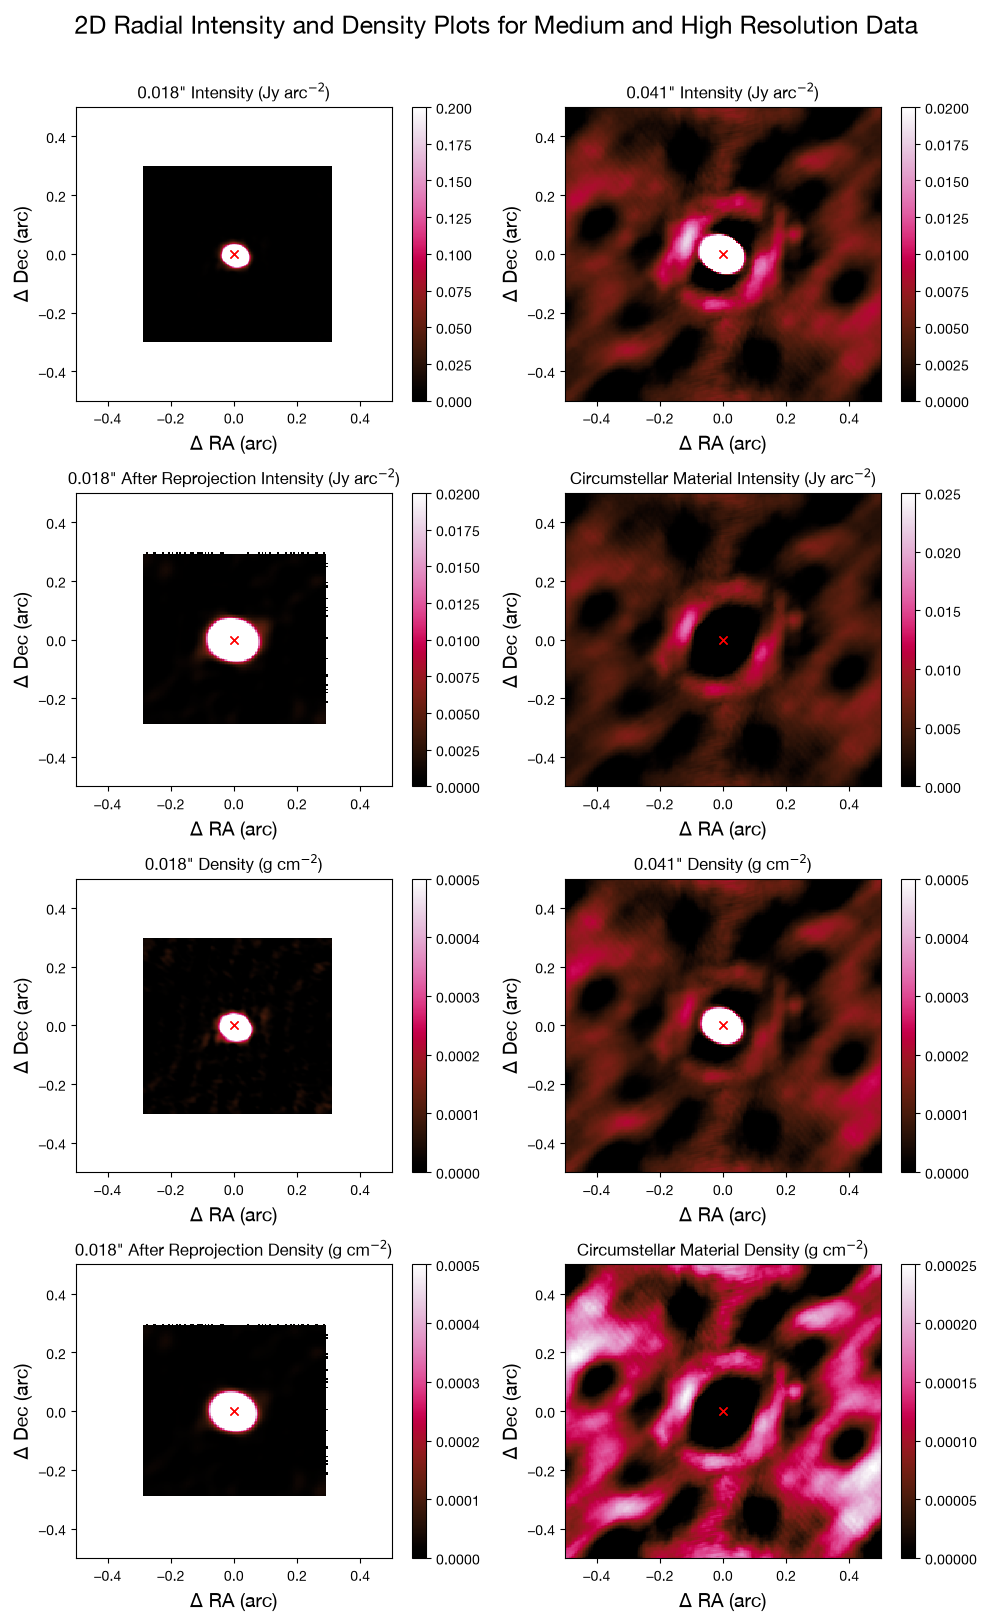

In [12]:
vminmax = [[0,.2], [0,.02],[0,.02],[0,0.025],
           [0,0.0005], [0,0.0005],[0,0.0005],[0,0.00025]]
plot_2d(data_plot3, info3, vminmax,minn=-.5, suptitle = "2D Radial Intensity and Density Plots for Medium and High Resolution Data")
#plt.savefig('thesis/medhigh/2D_plots_MH.png')

In [344]:
0.0295*2.5

0.07375

In [358]:
def plot12d2(data,info, suptitle,vminmax, minn=-.4, dense = False,companion_circle = False):
    maxx= -minn

    figure,ax = plt.subplots(nrows = 1, ncols=1, figsize = (5,4))#, subplot_kw={'projection': wcs})
    figure.suptitle(suptitle, fontsize = 18, y=1.01)

    xaxis = range(data.shape[0])*info['pix_size_arcsec']-((info['position'][0])*info['pix_size_arcsec'])
    yaxis = range(data.shape[1])*info['pix_size_arcsec']-((info['position'][1])*info['pix_size_arcsec'])


    im = ax.pcolormesh(yaxis,xaxis,data, cmap='gist_heat',shading="gouraud", vmin = vminmax[0], vmax = vminmax[1])
    # ax.plot((info['position'][1])*info['pix_size_arcsec']-((info['position'][1])*info['pix_size_arcsec']),
    #         (info['position'][0])*info['pix_size_arcsec']-((info['position'][0])*info['pix_size_arcsec']),'rx')
    # ax.plot(0,0,'rx')

    ax.set_xlim(minn, maxx)
    ax.set_ylim(minn, maxx)
    # plt.plot(476*info['pix_size_arcsec']-((info['position'][0])*info['pix_size_arcsec']),
    #          509*info['pix_size_arcsec']-((info['position'][1])*info['pix_size_arcsec']),'bx')
    #print(476*info['pix_size_arcsec']-((info['position'][0])*info['pix_size_arcsec']),
    #         509*info['pix_size_arcsec']-((info['position'][1])*info['pix_size_arcsec']))
    
    if(dense==False):
        figure.colorbar(im,ax=ax, label=r'Jy arc$^{-2}$')
    elif (dense == True):
        figure.colorbar(im,ax=ax, label=r'g cm$^{-2}$')

    if(companion_circle==True):
        companion_radius = plt.Circle((0, 0), 0.07, color='darkturquoise', fill=False)
        ax.add_patch(companion_radius)

    ax.set_xlabel(r'$\Delta$ RA (arc)' , size = 10)
    ax.set_ylabel(r'$\Delta$ Dec (arc)' , size = 10)



In [359]:
info3['hr']['position']

(np.int64(150), np.int64(144))

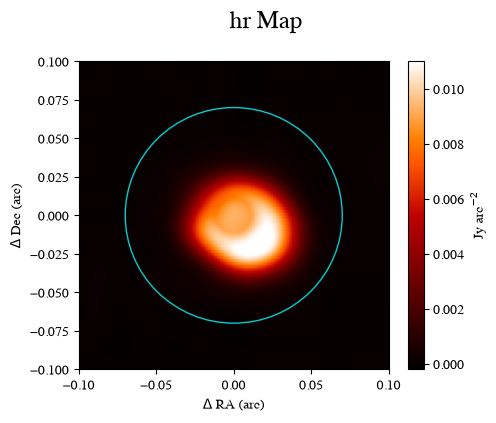

In [360]:
plot12d2(data_dens_2d3['hr'].value,info3['hr'],suptitle='hr Map', vminmax = [-0.0002,.011],minn=-.1,companion_circle=True)

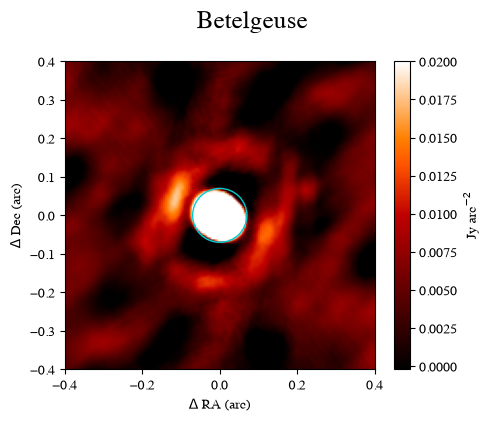

In [361]:
plot12d2(data3['lr']['jy_arc2'][0,0,...].value,info3['lr'],suptitle='Betelgeuse', vminmax = [-0.0002,0.02],minn=-.4,companion_circle=True)

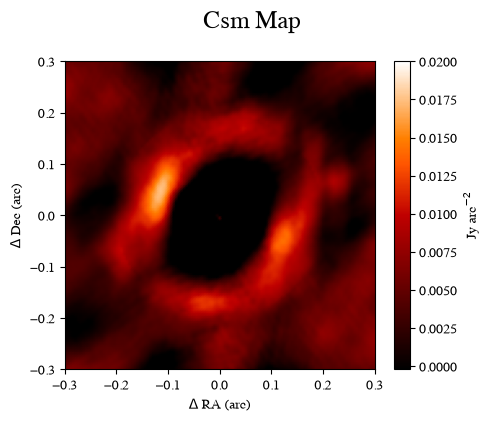

In [352]:
plot12d2(data3['csm']['jy_arc2'].value,info3['lr'],suptitle='Csm Map', vminmax = [-0.0002,0.02],minn=-.3)

In [18]:
info3['reproj']['pix_size_arcsec']

<Quantity 0.005 arcsec>

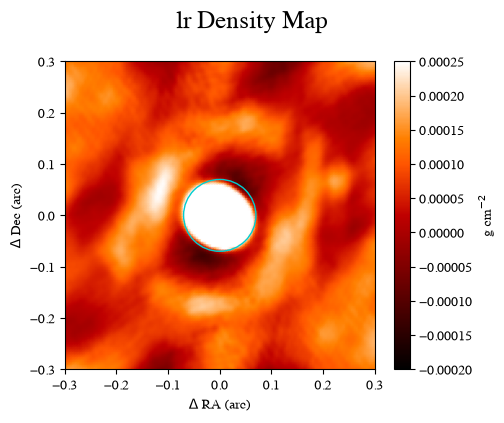

In [365]:
plot12d2(data_dens_2d3['lr'].value,info3['lr'],suptitle='lr Density Map', vminmax = [-0.0002,0.00025],minn=-0.3,dense=True,companion_circle=True)

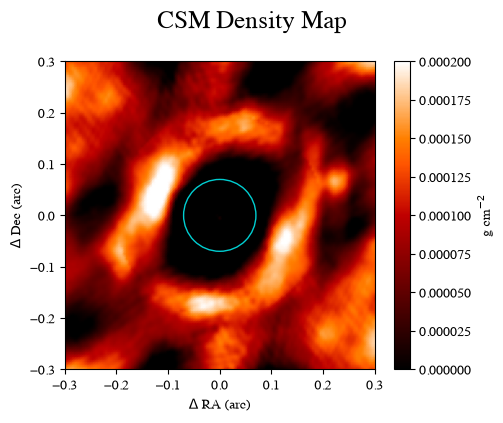

In [366]:
plot12d2(data_dens_2d3['csm'].value,info3['csm'],suptitle='CSM Density Map', vminmax = [0,0.0002],minn=-.3,dense=True,companion_circle=True)

In [21]:
data_dens_2d3['csm']

<Quantity [[ 3.59089411e-05,  2.30312811e-05,  1.64244097e-05, ...,
             4.41040161e-05,  4.35906691e-05,  4.21439657e-05],
           [ 4.60537599e-05,  3.42752638e-05,  2.52507845e-05, ...,
             4.47396901e-05,  4.88325941e-05,  4.66616748e-05],
           [ 5.17858186e-05,  4.38911284e-05,  3.50908807e-05, ...,
             4.38853955e-05,  4.61710080e-05,  4.46774098e-05],
           ...,
           [ 3.87969269e-05,  5.05893265e-05,  5.91705852e-05, ...,
             5.28625839e-06,  1.36623900e-05,  1.98688713e-05],
           [ 4.15442900e-05,  5.42086658e-05,  6.08186332e-05, ...,
            -2.96043274e-06,  4.55347428e-06,  9.47851110e-06],
           [ 4.55042668e-05,  5.56574725e-05,  6.07048501e-05, ...,
            -1.61377442e-05, -1.02610396e-05, -5.95204934e-06]] g / cm2>

In [22]:
info3['csm']['median_dens']

<Quantity 6.59685877e-05 g / cm2>

In [23]:
# np.savetxt("saved_data/csm_2d_density.csv", data_dens_2d3['csm'].value, 
#               delimiter = ",")
# np.savetxt("saved_data/hr_2d_density.csv", data_dens_2d3['hr'].value, 
#               delimiter = ",")
# np.savetxt("saved_data/lr_2d_density.csv", data_dens_2d3['lr'].value, 
#               delimiter = ",")
# np.savetxt("saved_data/reproj_2d_density.csv", data_dens_2d3['reproj'].value, 
#               delimiter = ",")

## Abel transform

In [24]:
## CUT IF ON HOME COMPUTER

In [25]:
cd /Users/ibehbehani/csm_pipeline

/Users/ibehbehani/csm_pipeline


In [26]:
from abel import all_abel, do_abel, plot_1d_abel

attempting to add a normalization step to account for negatives

In [27]:
def regularization(interp_data_original,radius_2d_arc,bkg,csm=False):
    '''
    interp_data_original: data in any units
    radius_2d_arc: radius in arcsec
    bkg: background median in same units as data
    '''
    interp_csm = np.zeros_like(radius_2d_arc)
    i_a=0
    i_b=0
    i_c=0
    

    radius_betel_arc = 0.295
 
    for i in range(radius_2d_arc.shape[0]):
        if csm==True:
                print(i)

        if radius_2d_arc[i]==0 and csm==True:
            interp_csm[i] = bkg*1e-3
            i_a+=1
        if i>=interp_data_original.shape[0]:
            interp_csm[i] = 1e-3*bkg/((radius_betel_arc/radius_2d_arc[i])**2)
            i_b+=1
        elif interp_data_original[i]<=0: # setting up power law background distribution # radius_2d_arc[i,j]<0.1 or 
            interp_csm[i] = 1e-3*bkg/((radius_betel_arc/radius_2d_arc[i])**2)
            i_b+=1
        elif  radius_2d_arc[i]<0.1 and csm==True:
            interp_csm[i] = 1e-3*bkg/((radius_betel_arc/radius_2d_arc[i])**2)
            i_b+=1
        else:
            #do nothing if normsl point
            interp_csm[i]=interp_data_original[i]
            i_c+=1

    # print(i_a)
    # print(i_b)
    # print(i_c)

    return interp_csm*u.gram/u.cm**2

In [28]:
d = {'hr': data_dens_1d3['hr'], 'lr': data_dens_1d3['lr'], 'reproj': data_dens_1d3['reproj'][~np.isnan(data_dens_1d3['reproj'])],"csm": data_dens_1d3['csm'][~np.isnan(data_dens_1d3['csm'])]}
i = {'hr': info3['hr'], 'lr': info3['lr'], 'reproj': info3['reproj'],"csm": info3['csm']}
title = ['hr','lr','reproj','csm']


In [29]:
# d = {}# regularized 1d surface density data
# csm_bool=False
# for t in range(4):
#     print(title[t])
#     if t == 3:
#         csm_bool=True
#     d[title[t]] = regularization(da[title[t]].value,radius3[title[t]]['arc_1d'].value, bkg = i[title[t]]['median_dens'].value,csm=csm_bool)

In [30]:
d['csm']

<Quantity [-3.31105249e-05, -9.27346103e-05, -2.08560839e-04,
           -3.56423024e-04, -5.19124301e-04, -6.71140774e-04,
           -7.81443928e-04, -8.26388746e-04, -8.02597209e-04,
           -7.21776149e-04, -6.04697121e-04, -4.75472563e-04,
           -3.55232980e-04, -2.54572088e-04, -1.74819205e-04,
           -1.15056197e-04, -7.19011687e-05, -3.87021012e-05,
           -1.11625798e-05,  1.26073533e-05,  3.39226505e-05,
            5.31928284e-05,  7.00176830e-05,  8.46691300e-05,
            9.71101947e-05,  1.06674775e-04,  1.13355151e-04,
            1.18157696e-04,  1.22389558e-04,  1.26331170e-04,
            1.29363049e-04,  1.31221220e-04,  1.31911926e-04,
            1.30756934e-04,  1.27906909e-04,  1.23823807e-04,
            1.18415929e-04,  1.11630675e-04,  1.03926853e-04,
            9.60414953e-05,  8.80689157e-05,  8.12693443e-05,
            7.60502392e-05,  7.24237079e-05,  6.97021740e-05,
            6.75163556e-05,  6.57578499e-05,  6.45586359e-05,
        

Text(0, 0.5, 'Density (g cm$^{-3}$)')

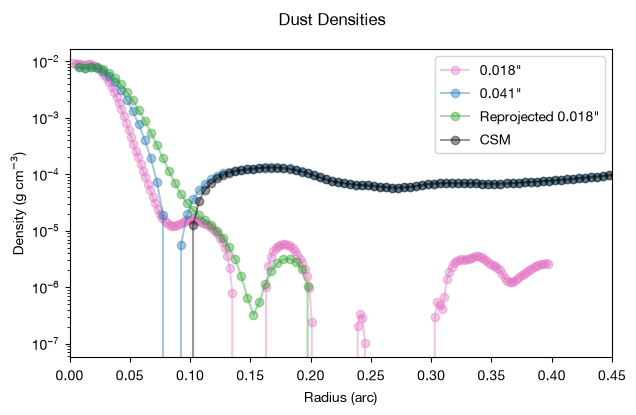

In [31]:
fig, ax = plt.subplots(1, 1, figsize = [7,4])
fig.suptitle("Dust Densities")

title = ['hr','lr','reproj','csm']
labels = ['{res}"'.format(res = np.round(i['hr']['kspatres'],3)),
            '{res}"'.format(res = np.round(i['lr']['kspatres'],3)),
            'Reprojected {res}"'.format(res = np.round(i['hr']['kspatres'],3)),
            "CSM"]    

color = ['C6','C0','C2','black']

for j in range(len(title)):
        #print(radius3[title[j]])
        ax.plot(radius3[title[j]]['arc_1d'][:len(d[title[j]])],d[title[j]],'o-',alpha=0.4, label = labels[j], c = color[j])



ax.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
ax.set_xlim(0,0.45)

#ax.set_ylim(-1e-22, 1e-3)

ax.semilogy()

ax.set_xlabel('Radius (arc)')
ax.set_ylabel(r'Density (g cm$^{-3}$)')

#fig.show()

Text(0, 0.5, 'Density (g cm$^{-3}$)')

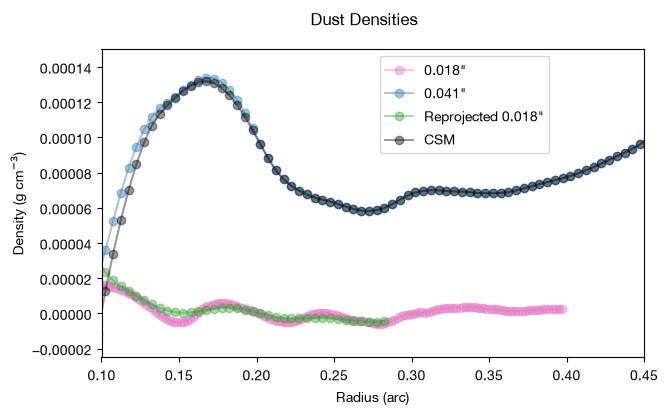

In [32]:
fig, ax = plt.subplots(1, 1, figsize = [7,4])
fig.suptitle("Dust Densities")

title = ['hr','lr','reproj','csm']
labels = ['{res}"'.format(res = np.round(i['hr']['kspatres'],3)),
            '{res}"'.format(res = np.round(i['lr']['kspatres'],3)),
            'Reprojected {res}"'.format(res = np.round(i['hr']['kspatres'],3)),
            "CSM"]    

color = ['C6','C0','C2','black']

for j in range(len(title)):
        #print(radius3[title[j]])
        ax.plot(radius3[title[j]]['arc_1d'][:len(d[title[j]])],d[title[j]],'o-',alpha=0.4, label = labels[j], c = color[j])



ax.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
ax.set_xlim(0.1,0.45)

lim = 5e-4
ax.set_ylim(-0.000025, 0.00015)


ax.set_xlabel('Radius (arc)')
ax.set_ylabel(r'Density (g cm$^{-3}$)')

#fig.show()

In [33]:
d['reproj']<0

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True])

In [34]:
# def normalize(d):
#     titles = list(d.keys())
#     for t in titles:
#         d[t] = ((d[t] - d[t].min()) / (d[t].max() - d[t].min()))*d[t].max()
#         print(t, np.nanmin(d[t].value),np.nanmax(d[t].value))


In [35]:
#normalize(d)

Text(0, 0.5, 'Density (g cm$^{-3}$)')

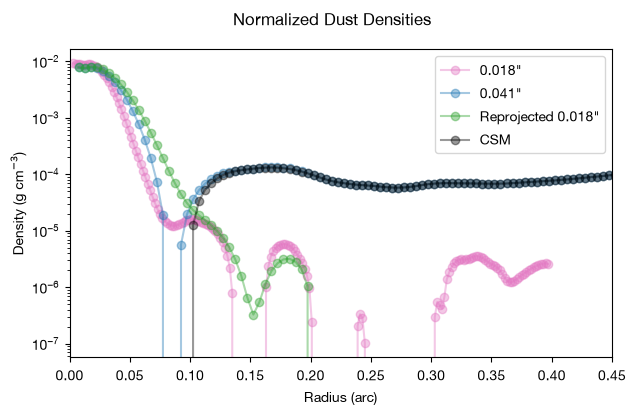

In [36]:
fig, ax = plt.subplots(1, 1, figsize = [7,4])
fig.suptitle("Normalized Dust Densities")

for j in range(len(title)):
        #print(radius3[title[j]])
        ax.plot(radius3[title[j]]['arc_1d'][:len(d[title[j]])],d[title[j]],'o-',alpha=0.4, label = labels[j], c = color[j])



ax.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
ax.set_xlim(0,0.45)

ax.semilogy()
ax.set_xlabel('Radius (arc)')
ax.set_ylabel(r'Density (g cm$^{-3}$)')

#fig.show()

In [37]:
d['csm']

<Quantity [-3.31105249e-05, -9.27346103e-05, -2.08560839e-04,
           -3.56423024e-04, -5.19124301e-04, -6.71140774e-04,
           -7.81443928e-04, -8.26388746e-04, -8.02597209e-04,
           -7.21776149e-04, -6.04697121e-04, -4.75472563e-04,
           -3.55232980e-04, -2.54572088e-04, -1.74819205e-04,
           -1.15056197e-04, -7.19011687e-05, -3.87021012e-05,
           -1.11625798e-05,  1.26073533e-05,  3.39226505e-05,
            5.31928284e-05,  7.00176830e-05,  8.46691300e-05,
            9.71101947e-05,  1.06674775e-04,  1.13355151e-04,
            1.18157696e-04,  1.22389558e-04,  1.26331170e-04,
            1.29363049e-04,  1.31221220e-04,  1.31911926e-04,
            1.30756934e-04,  1.27906909e-04,  1.23823807e-04,
            1.18415929e-04,  1.11630675e-04,  1.03926853e-04,
            9.60414953e-05,  8.80689157e-05,  8.12693443e-05,
            7.60502392e-05,  7.24237079e-05,  6.97021740e-05,
            6.75163556e-05,  6.57578499e-05,  6.45586359e-05,
        

In [38]:
#without norm
print(info3['hr']['median'])
print(info3['reproj']['median'])
print(info3['lr']['median'])
print(info3['csm']['median'])


2.7049269580517033e-05
8.418014260236199e-05
0.0010701067859508304
0.0010686996310676836


In [39]:
#with norm
print(info3['hr']['median'])
print(info3['reproj']['median'])
print(info3['lr']['median'])
print(info3['csm']['median'])

2.7049269580517033e-05
8.418014260236199e-05
0.0010701067859508304
0.0010686996310676836


In [40]:
#without norm
print(info3['hr']['median_dens'])
print(info3['reproj']['median_dens'])
print(info3['lr']['median_dens'])
print(info3['csm']['median_dens'])


8.773863086349733e-07 g / cm2
1.493734508648048e-06 g / cm2
6.603274608302551e-05 g / cm2
6.596858769730813e-05 g / cm2


In [41]:
#with norm
print(info3['hr']['median_dens'])
print(info3['reproj']['median_dens'])
print(info3['lr']['median_dens'])
print(info3['csm']['median_dens'])


8.773863086349733e-07 g / cm2
1.493734508648048e-06 g / cm2
6.603274608302551e-05 g / cm2
6.596858769730813e-05 g / cm2


In [42]:
csm_bkg = np.sqrt(info3['reproj']['median_dens']**2+info3['lr']['median_dens']**2)

In [43]:
def all_abel(data,rad,info):
    print("here i am!")
    titles = list(data.keys())
    f_rs = {}
    r_s = {}
    r_s_pc = {}

    for t in titles:
        print(t)
        print("max:", np.nanmax(data[t].value))
        print("median dens: ", info[t]['median_dens'])
        if(t=="csm"):
            print("CSM")
            f_rs[t],r_s[t],r_s_pc[t] = do_abel(data[t].value,rad[t]['pc_1d'].to(u.cm).value,info[t]['median_dens']/100)

            #f_rs[t] = do_abel(data[t].value,rad[t]['pc_1d'].to(u.cm).value,csm_bkg)
        else:
            f_rs[t],r_s[t],r_s_pc[t] = do_abel(data[t].value,rad[t]['pc_1d'].to(u.cm).value,info[t]['median_dens'])
        # print('\n')
        # print(t)
        # print('f_rs',f_rs[t])
        # print('r_s',r_s[t])
        # print('\n')

    return f_rs,r_s, r_s_pc



def do_abel(F_arr,s,med):
    '''
    F = radial profile of surface density
    s = radii corresponding with radial profile
    med = background median- sets all neg values in F array to bkg median
    '''
    print()
    med = med/10
    
    F = F_arr.copy() # copy density array to prevent overwriting
    F[F<0] =0#med # turn negative values into background median
    s = s[:len(F)]
    dF_ds = np.gradient(F,s) 
    ##dF_ds = dF_ds[~np.isnan(dF_ds)] #this likely only works for this data bc it 
    ##s = s[:len(dF_ds)] # only cuts off nans if theyre all at the end of image
    #print(s)
    f_r = np.zeros(len(s)-1)
    r_arr = np.zeros(len(s)-1)
    #print(dF_ds)

    print(len(s))

    for i in range(len(s)-1):
        r = (s[i]+s[i+1])/2
        r_arr[i] = r

        integ = np.trapezoid(dF_ds[i+1:]/ np.sqrt(s[s>r]**2-r**2),s[s>r])

        f_r[i]= (-1/np.pi)* integ # integrate from r to highest radial value

        print(i, r_arr[i],f_r[i])
        #print(i,F_arr[i],F[i],dF_ds[i])

        
    r_cm = r_arr*u.cm
    r_pc = r_cm.to(u.pc)

    r_arc = (r_pc *206265*u.arcsec) / (168*u.pc)
    # print(r_cm)
    # print(f_r)

    return f_r, r_arc, r_pc

In [44]:
abels,r_abels, r_abel_pc = all_abel(d,radius3,i)

here i am!
hr
max: 0.009254187509873982
median dens:  8.773863086349733e-07 g / cm2

198
0 10052967467880.467 4.376263587853971e-17
1 15079451201820.7 4.1778974253225654e-17
2 20105934935760.934 3.8649184332493933e-17
3 25132418669701.168 3.5491061653097234e-17
4 30158902403641.4 3.6689480978502635e-17
5 35185386137581.63 4.148616702557844e-17
6 40211869871521.87 4.541142045260484e-17
7 45238353605462.09 4.740191050112498e-17
8 50264837339402.33 4.76580802589567e-17
9 55291321073342.57 4.6403208170676206e-17
10 60317804807282.8 4.389961528874456e-17
11 65344288541223.03 4.044083196444636e-17
12 70370772275163.27 3.632860127941883e-17
13 75397256009103.5 3.18561207084638e-17
14 80423739743043.72 2.7288313685744026e-17
15 85450223476983.97 2.284714609528524e-17
16 90476707210924.2 1.8708435054268892e-17
17 95503190944864.44 1.49935695569212e-17
18 100529674678804.67 1.1773650334031977e-17
19 105556158412744.89 9.071826496443724e-18
20 110582642146685.12 6.8715343577893815e-18
21 11560912

In [45]:
def howmanynan(d):
    titles = list(d.keys())

    for t in titles:
        print(t)
        print('Not nans: ',np.count_nonzero(~np.isnan(d[t])))
        print('Nans: ', np.count_nonzero(np.isnan(d[t])))
        print('\n')

In [46]:
def how_many_zero(d):
    titles = list(d.keys())

    for t in titles:
        print(t)
        print('len', len(d[t]))
        print('Nonzero: ',np.count_nonzero(d[t]))
        print('Zero: ', len(d[t])-np.count_nonzero(d[t]))
        print('\n')

In [47]:
print("nans in 1d surface density profile")
howmanynan(d)

nans in 1d surface density profile
hr
Not nans:  198
Nans:  0


lr
Not nans:  198
Nans:  0


reproj
Not nans:  56
Nans:  0


csm
Not nans:  198
Nans:  0




In [48]:
print("zeroes in 1d IAT density profiles")
how_many_zero(abels)

zeroes in 1d IAT density profiles
hr
len 197
Nonzero:  196
Zero:  1


lr
len 197
Nonzero:  196
Zero:  1


reproj
len 55
Nonzero:  39
Zero:  16


csm
len 197
Nonzero:  196
Zero:  1




In [49]:
abels['reproj']

array([ 2.43018134e-17,  2.72480955e-17,  3.00300007e-17,  2.89955571e-17,
        2.57236563e-17,  2.13413665e-17,  1.66987536e-17,  1.23784100e-17,
        8.71761023e-18,  5.84928494e-18,  3.74851493e-18,  2.30260424e-18,
        1.36194362e-18,  7.80476428e-19,  4.38386080e-19,  2.45636525e-19,
        1.41377954e-19,  8.69025398e-20,  5.89963091e-20,  4.44534942e-20,
        3.60239149e-20,  2.99909176e-20,  2.45869820e-20,  1.91589816e-20,
        1.36743158e-20,  8.43237452e-21,  3.87263345e-21,  4.22017759e-22,
       -1.62300931e-21, -2.18230133e-21, -1.42397762e-21,  2.66534974e-22,
        2.36622062e-21,  4.31898196e-21,  5.63852656e-21,  5.98707688e-21,
        5.20394824e-21,  3.30241268e-21,  1.04034608e-21, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -

In [50]:
abels['csm']

array([-1.02812001e-19, -1.03429174e-19, -1.04310186e-19, -1.05473137e-19,
       -1.06943052e-19, -1.08753491e-19, -1.10948887e-19, -1.13587999e-19,
       -1.16749078e-19, -1.20537804e-19, -1.25099927e-19, -1.30642347e-19,
       -1.37470418e-19, -1.46059361e-19, -1.57206723e-19, -1.72415325e-19,
       -1.95166455e-19, -2.21231791e-19, -2.23216800e-19, -1.89745047e-19,
       -1.45153361e-19, -1.05001067e-19, -6.91312572e-20, -3.74113378e-20,
       -1.14330587e-20,  7.55960831e-21,  2.11748218e-20,  3.29215584e-20,
        4.49535346e-20,  5.68039758e-20,  6.75324081e-20,  7.66834835e-20,
        8.31163190e-20,  8.61636729e-20,  8.63887956e-20,  8.37844867e-20,
        7.77622503e-20,  6.85531436e-20,  5.70960867e-20,  4.41709730e-20,
        3.15242029e-20,  2.11989876e-20,  1.37883835e-20,  8.58336970e-21,
        4.54096213e-21,  1.33597614e-21, -9.00256108e-22, -2.61806643e-21,
       -4.85946078e-21, -7.93628388e-21, -1.15102642e-20, -1.50033631e-20,
       -1.77315132e-20, -

In [51]:
from radial_regularization import sm

In [ ]:
def plot_1d_abel_rs(data_abel_1d,info,radius,ax_ymin=1e-2, ax_ymax=1e4,xmin=0,xmax=0.45, suptitle = "1D Abel Transformation (g/cm3)", dent=False):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''


    plt.rcParams["font.family"] = "times"
    fig, ax = plt.subplots(1, 1, figsize = [7,4])
    fig.suptitle(suptitle)

    title = ['hr','lr','reproj','csm']
    labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
             '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
             'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
             "CSM"]    
    
    color = ['C6','C0','C2','black']

    for j in range(len(title)):
            # print(title[j])
            # rad_pc = radius[title[j]].to(u.pc)
            # print(rad_pc.value)
            # rad_arc = rad_pc *206265 / 168
            ax.plot(radius[title[j]],data_abel_1d[title[j]],'o-',alpha=0.4, label = labels[j], c = color[j])
            #ax.errorbar(radius[title[c]]['arc_1d'],data_1d[title[c]].value,yerr=info[title[c]]['error'].value, c = color[c])

    

    if(dent == True):
         m_e = 9.109e-28 # electron mass in g
         m_p = 1.6726e-24
         plt.axhline(y=(m_e+m_p)*3e8/(0.7), label = "Dent 2025",color = 'black', ls = ':')
         plt.axhline(y=(m_e+m_p)*2e8/(0.7), label = "Judge 1998", color = 'red', ls = '--')
         plt.axhline(y=(m_e+m_p)*1e9/(0.7), label = "Harper 2006", color = 'orange',ls = '-.')



    ax.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
    ax.set_xlim(xmin,xmax)
    #ax.set_xlim(0,0.45)

    ax.set_ylim(ax_ymin, ax_ymax)

    ax.semilogy()

    ax.set_xlabel('Radius (arc)')
    ax.set_ylabel(r'Density (g cm$^{-3}$)')

    fig.show()

In [201]:
def plot_1d_abel_rs_double(dust_dens,info,radius,ax_ymin=1e-2, ax_ymax=1e4,xmin=0,xmax=0.45, suptitle = "1D Abel Transformation (g/cm3)", dent=False):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''


    plt.rcParams["font.family"] = "times"
    fig, (ax,ax1) = plt.subplots(2, sharex=True, figsize = [5,7])
    fig.suptitle(suptitle)

    title = ['hr','lr','reproj','csm']
    color = ['C6','C0','C2','mediumorchid']
    markers = ['*', 'o', 'v', '^']
    lines = ['solid','solid','solid',(0,(1,1)) ]
    labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
                 '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
                 'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
                 "CSM"]  
    
    
    for j in range(len(title)):
        #print(radius3[title[j]])
        ax.plot(radius[title[j]]['arc_1d'][:len(dust_dens[title[j]])],dust_dens[title[j]],'o-',alpha=0.4, label = labels[j], c = color[j])

    ax.legend(loc = 'upper right')#, bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ax_ymin, ax_ymax)

    ax.semilogy()
    ax.semilogx()
    ax.set_title("Surface Dust Density Distribution")

    #ax.set_xlabel('Radius (arc)')
    ax.set_ylabel(r'Density (g cm$^{-2}$)')

    # for bottom panel
    ax1.set_title("Volumetric Dust Density Distribution")
    for j in range(len(title)):
        #print(radius3[title[j]])
        
        ax1.plot(radius[title[j]]['arc_1d'][:len(abels[title[j]])],abels[title[j]],'o-',markersize=1,
                 linewidth = 3, alpha=0.4, label = labels[j], c = color[j],linestyle = lines[j])




        #ax1.legend(loc = 'best', bbox_to_anchor=(0.5, 0.5, 0.5, 0.5))
    ax1.set_xlim(xmin,xmax)

    ax1.set_ylim(5e-22, 1e-14)
    #ax1.set_ylim(5e-22, 1e-18)
    # ch= 1e-19
    # ax1.set_ylim(-ch,ch)
    #ax1.set_ylim(-1e-20,1e-20)

    ax1.semilogy()
    ax1.semilogx()
    #ax1.axvline(29.5)

    ax1.set_xlabel('Radius (mas)')
    ax1.set_ylabel(r'Density (g cm$^{-3}$)')

    #plot_1d_abel_massloss_bkg_for_double(abels,info3,radius,ax1,ax_ymin=1e-20,ax_ymax=1e-12, xmin= 1*10**-2.2,xmax=xmax, suptitle = "1D Inverse Abel Transform for Medium and High Resolution Gas and Dust" ,dent = True)


    fig.show()

/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/2338416797.py:42: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  ax1.plot(radius[title[j]]['arc_1d'][:len(abels[title[j]])],abels[title[j]],'o-',markersize=1,
/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/2338416797.py:67: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


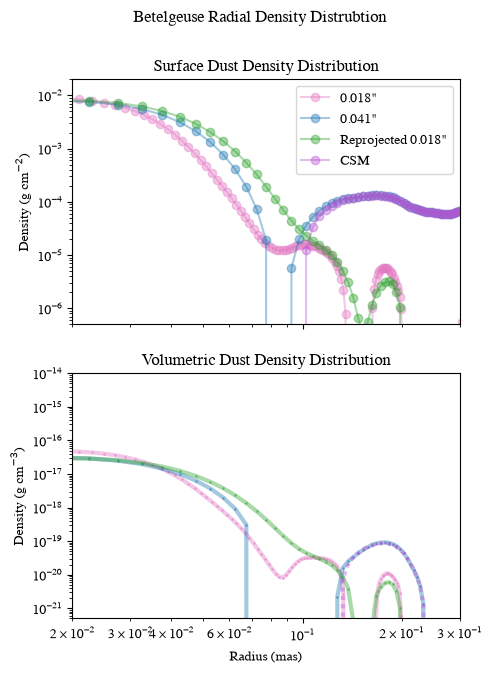

In [202]:
plot_1d_abel_rs_double(d,info3,radius3, ax_ymin=5e-7,ax_ymax=2e-2,xmin=0.02,xmax=0.3,suptitle = "Betelgeuse Radial Density Distrubtion",dent = True) #ax_ymin=5e-5,ax_ymax=2e-4,xmin=.09,xmax=1,


/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/1954292384.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


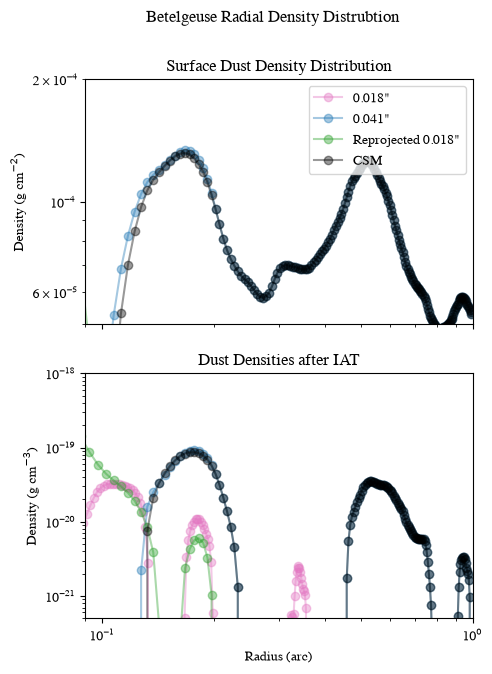

In [55]:
plot_1d_abel_rs_double(d,info3,radius3,ax_ymin=5e-5,ax_ymax=2e-4,xmin=.09,xmax=1,suptitle = "Betelgeuse Radial Density Distrubtion") #ax_ymin=5e-5,ax_ymax=2e-4,xmin=.09,xmax=1,


/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/1954292384.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


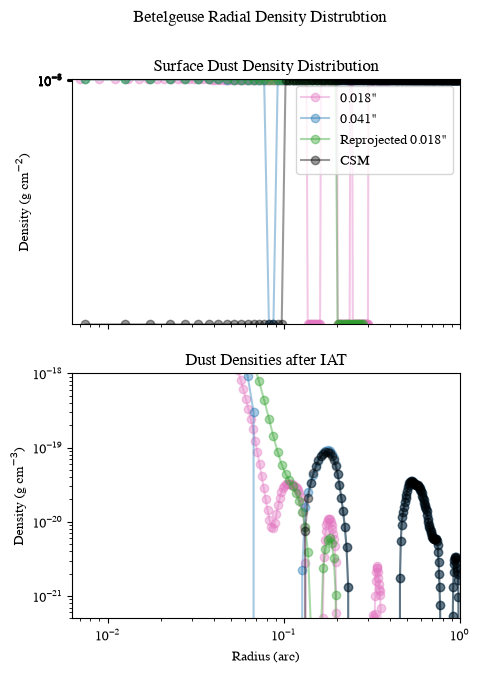

In [56]:
plot_1d_abel_rs_double(d,info3,radius3, ax_ymin=-1e-3,ax_ymax=1e-2,xmin=1*10**-2.2,xmax=1,suptitle = "Betelgeuse Radial Density Distrubtion") #ax_ymin=5e-7,ax_ymax=2e-2,xmin=1*10**-2.2,xmax=1,


/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/1954292384.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


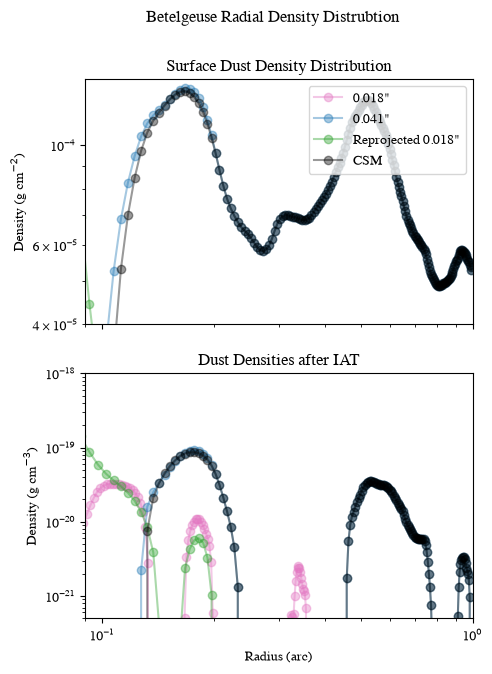

In [57]:
plot_1d_abel_rs_double(d,info3,radius3, ax_ymin=4e-5,ax_ymax=1.4e-4,xmin=.09,xmax=1,suptitle = "Betelgeuse Radial Density Distrubtion") #ax_ymin=5e-5,ax_ymax=2e-4,xmin=.09,xmax=1,


In [58]:
abels['reproj']

array([ 2.43018134e-17,  2.72480955e-17,  3.00300007e-17,  2.89955571e-17,
        2.57236563e-17,  2.13413665e-17,  1.66987536e-17,  1.23784100e-17,
        8.71761023e-18,  5.84928494e-18,  3.74851493e-18,  2.30260424e-18,
        1.36194362e-18,  7.80476428e-19,  4.38386080e-19,  2.45636525e-19,
        1.41377954e-19,  8.69025398e-20,  5.89963091e-20,  4.44534942e-20,
        3.60239149e-20,  2.99909176e-20,  2.45869820e-20,  1.91589816e-20,
        1.36743158e-20,  8.43237452e-21,  3.87263345e-21,  4.22017759e-22,
       -1.62300931e-21, -2.18230133e-21, -1.42397762e-21,  2.66534974e-22,
        2.36622062e-21,  4.31898196e-21,  5.63852656e-21,  5.98707688e-21,
        5.20394824e-21,  3.30241268e-21,  1.04034608e-21, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -0.00000000e+00, -0.00000000e+00, -0.00000000e+00,
       -0.00000000e+00, -

In [59]:
np.nanmax(abels['reproj'])/np.nanmax(abels['csm'])

np.float64(347.61453121029496)

In [60]:
np.nanmax(d['reproj'])/np.nanmax(d['csm'])

<Quantity 61.23245312>

/var/folders/bd/zqhz_9jx7gn5z5xnr8ynvz5h0000gn/T/ipykernel_50018/1559717870.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


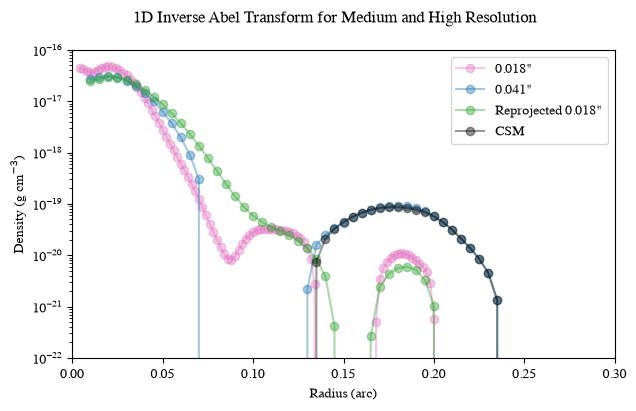

In [61]:
plot_1d_abel_rs(abels,info3,r_abels,ax_ymin=1e-22,ax_ymax=1e-16,xmax=0.3, suptitle = "1D Inverse Abel Transform for Medium and High Resolution")


In [152]:
5

5

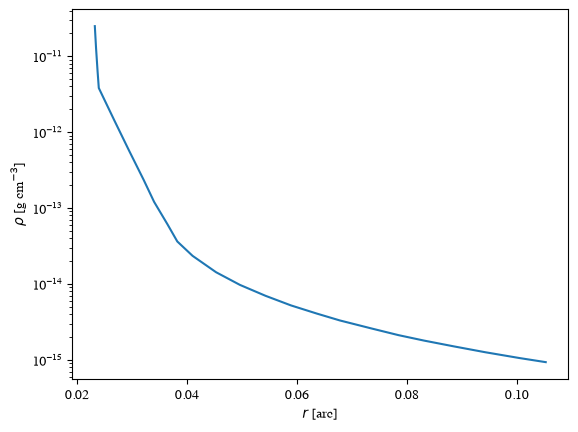

In [198]:
# H density from Dent et al via webplotdigitizer
data = np.asarray([[1.0801033591731268, 13.018018018018019],
[1.0904392764857884, 12.729729729729732],
[1.103359173126615, 12.423423423423424],
[1.1136950904392768, 12.202702702702704],
[1.245478036175711, 11.774774774774775],
[1.3695090439276487, 11.378378378378379],
[1.4935400516795867, 10.99099099099099],
[1.5813953488372094, 10.702702702702704],
[1.6950904392764858, 10.405405405405405],
[1.7777777777777781, 10.18018018018018],
[1.9069767441860466, 9.99099099099099],
[2.1059431524547803, 9.774774774774775],
[2.30749354005168, 9.608108108108109],
[2.524547803617571, 9.463963963963964],
[2.739018087855297, 9.337837837837839],
[2.9586563307493536, 9.22972972972973],
[3.152454780361757, 9.13963963963964],
[3.4263565891472867, 9.031531531531531],
[3.648578811369509, 8.945945945945946],
[3.8656330749354, 8.873873873873872],
[4.118863049095607, 8.797297297297298],
[4.3824289405684755, 8.72072072072072],
[4.671834625322997, 8.644144144144143],
[4.89405684754522, 8.59009009009009],]).T

# pN = mr.MesaData()

fig, ax = plt.subplots()
dxaxis = data[0]*21.5/1000
dyaxis = 10**data[1] * 1.6735575e-24 * (1/0.7)
# ax.plot([2*scale,4*scale], [1e-13, 1e-13/4], linestyle='dashed', color='k')
# ax.plot([2*scale,4*scale], [1e-13, 1e-13/8], linestyle='dashed', color='k')
ax.plot(dxaxis, dyaxis)
# ax.set_xscale('log')
ax.set_yscale('log')
#ax.set_xscale('log')
ax.set_xlabel(r'$r$ [arc]')
ax.set_ylabel(r'$\rho$ [g cm$^{-3}$]')
plt.show()

In [ ]:
def plot_1d_abel_massloss_bkg(data_abel_1d,info,radius,ax_ymin=1e-2, ax_ymax=1e4,xmin=0,xmax=0.45, suptitle = "1D Abel Transformation (g/cm3)", dent=False):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''

    fig, ax = plt.subplots(1, 1, figsize = [7,4])
    #fig.suptitle(suptitle)

    unit_scaler = 1000 #convert to mas?
    title = ['hr','lr','reproj','csm']
    # labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #          '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
    #            'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #              "CSM"]    
    labels = ['{res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))),
                 '{res} mas'.format(res = int(np.round(info['lr']['kspatres']*unit_scaler,decimals=0))),
                   'Reprojected {res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))),
                     "CSM"]    
    
    for j in range(len(title)):
 
        ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])]/0.0295,data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])

        #ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])],data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])


    x = (radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])]).value
    increment = np.arange(0,len(x),x[1]-x[0])
    #y = (data_abel_1d[title[j]][0]*716)*(10)**(-x) #abels['hr'][0]
    y = (data_abel_1d['lr'][0]*716)*10**(-x)
 

    xlr = (radius[title[j]]['arc_1d'][:len(abels['lr'])]).value    
    xlr_cm = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.cm)    
    xlr_rsun = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.Rsun)  
    dlr = np.gradient(abels['lr']*716,0.005)
    # # print("dlr", dlr)
    # # print("y!",716*abels['lr'][0]*10**(dlr*xlr))

    v_yr = (1e6*u.cm/u.s).to(u.cm/u.yr)
    v_s = (1e6*u.cm/u.s)

    #Mlr = radius3['lr']['pc_1d'].to(u.cm)**2* (716*abels['lr']*u.g/u.cm**3).to(u.M_sun/u.cm**3) *4*np.pi*(1e6*u.cm/u.s).to(u.cm/u.yr)
    
    #ax.plot(xlr, Mlr.to(u.g/u.s) / (4*np.pi*xlr_cm**2*v_s), label = r'$\dot M = 4 \pi r^2 \rho v$')
    if(dent == True):
            m_e = 9.109e-28 # electron mass in g
            m_p = 1.6726e-24
            ax.plot(dxaxis/0.0295,dyaxis, label = ("Dent 2024"),color = 'darkred',alpha = 0.4, ls='dashed')

    mdotexp = [-8,-7,-6,-5,-4]# msun/yr

    for mdot in mdotexp:
        print(mdot)

        rho_mdot = 10**mdot*u.M_sun/u.yr / (4*np.pi*xlr_cm**2*v_yr)
        ax.plot(xlr, rho_mdot.to(u.g/u.cm**3).value, ls  = '-.',alpha = 0.6, c='grey')

        xtext = xlr[1]
        ytext = rho_mdot[35].to(u.g/u.cm**3)+rho_mdot[1].to(u.g/u.cm**3)/13

        print(xtext,ytext)


        ax.text(xtext,ytext, f'$10^{{{mdot}}}$'+r' $M_\odot yr^{-1}$', fontsize=9, 
                rotation=-10, alpha = 0.6)


    # ax.plot(xlr, 716*abels['lr'][0]*10**(dlr*xlr), color = 'gray', ls  = '--', label = 'LR deriv ~10**(-13)')
    ax.legend(loc='upper right')#bbox_to_anchor=(1.35, 1),
    #, bbox_to_anchor=(.85, 0.5, 0.5, 0.5))
    ax.semilogy()
    ax.semilogx()
#     ax.set_title("1-D Density (g/cm3)")
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ax_ymin, ax_ymax)

    ax.axvline(x=1, c = 'red', label = 'R_star = 1', ls = 'dashed')

    ax.set_xlabel('Radius (arcseconds)')
    ax.set_xlabel(r'Radius [$R_{*}$]')
    ax.set_ylabel(r'Density (g cm$^{-3}$)')

In [262]:
def plot_1d_abel_massloss_bkg(data_abel_1d,info,radius,ax_ymin=1e-2, ax_ymax=1e4,xmin=0,xmax=0.45, suptitle = "1D Abel Transformation (g/cm3)", dent=False):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''

    fig, ax = plt.subplots(1, 1, figsize = [7,4])
    #fig.suptitle(suptitle)

    unit_scaler = 1000 #convert to mas?
    title = ['hr','lr','reproj','csm']
    # labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #          '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
    #            'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #              "CSM"]    
    labels = ['{res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))),
                 '{res} mas'.format(res = int(np.round(info['lr']['kspatres']*unit_scaler,decimals=0))),
                   'Reprojected {res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))
                                                  ),
                     "CSM"]    
    
    for j in range(len(title)):
 
        ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])],data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])

        #ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])],data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])


    x = (radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])]).value
    increment = np.arange(0,len(x),x[1]-x[0])
    #y = (data_abel_1d[title[j]][0]*716)*(10)**(-x) #abels['hr'][0]
    y = (data_abel_1d['lr'][0]*716)*10**(-x)
 

    xlr = (radius[title[j]]['arc_1d'][:len(abels['lr'])]).value    
    xlr_cm = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.cm)    
    xlr_rsun = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.Rsun)  
    dlr = np.gradient(abels['lr']*716,0.005)
    # # print("dlr", dlr)
    # # print("y!",716*abels['lr'][0]*10**(dlr*xlr))

    v_yr = (1e6*u.cm/u.s).to(u.cm/u.yr)
    v_s = (1e6*u.cm/u.s)

    #Mlr = radius3['lr']['pc_1d'].to(u.cm)**2* (716*abels['lr']*u.g/u.cm**3).to(u.M_sun/u.cm**3) *4*np.pi*(1e6*u.cm/u.s).to(u.cm/u.yr)
    
    #ax.plot(xlr, Mlr.to(u.g/u.s) / (4*np.pi*xlr_cm**2*v_s), label = r'$\dot M = 4 \pi r^2 \rho v$')
    if(dent == True):
            m_e = 9.109e-28 # electron mass in g
            m_p = 1.6726e-24
            ax.plot(dxaxis,dyaxis, label = ("Dent 2024"),color = 'darkred',alpha = 0.4, ls='dashed')

    mdotexp = [-8,-7,-6,-5,-4]# msun/yr

    for mdot in mdotexp:
        print(mdot)

        rho_mdot = 10**mdot*u.M_sun/u.yr / (4*np.pi*xlr_cm**2*v_yr)
        ax.plot(xlr, rho_mdot.to(u.g/u.cm**3).value, ls  = '-.',alpha = 0.6, c='grey')

        xtext = xlr[1]
        ytext = rho_mdot[35].to(u.g/u.cm**3)+rho_mdot[1].to(u.g/u.cm**3)/13

        print(xtext,ytext)


        ax.text(xtext,ytext, f'$10^{{{mdot}}}$'+r' $M_\odot yr^{-1}$', fontsize=9, 
                rotation=-15, alpha = 0.6)


    # ax.plot(xlr, 716*abels['lr'][0]*10**(dlr*xlr), color = 'gray', ls  = '--', label = 'LR deriv ~10**(-13)')
    ax.legend(loc='upper right')#bbox_to_anchor=(1.35, 1),
    #, bbox_to_anchor=(.85, 0.5, 0.5, 0.5))
    ax.semilogy()
    ax.semilogx()
#     ax.set_title("1-D Density (g/cm3)")
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ax_ymin, ax_ymax)


    ax.set_xlabel('Radius (arcseconds)')
    ax.set_ylabel(r'Density (g cm$^{-3}$)')

-8
0.012500000000001 4.1463906183997455e-18 g / cm3
-7
0.012500000000001 4.1463906183997455e-17 g / cm3
-6
0.012500000000001 4.1463906183997457e-16 g / cm3
-5
0.012500000000001 4.146390618399746e-15 g / cm3
-4
0.012500000000001 4.146390618399746e-14 g / cm3


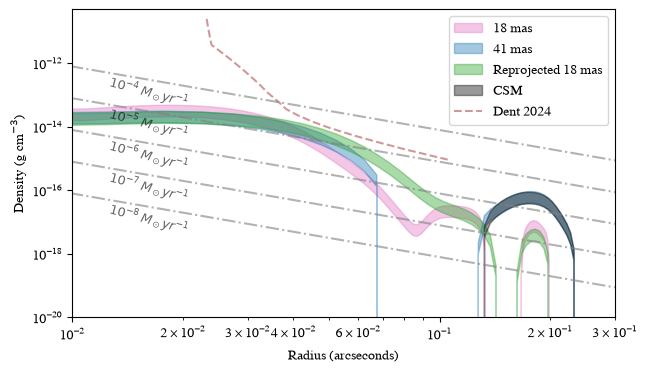

In [263]:
plot_1d_abel_massloss_bkg(abels,info3,radius3,ax_ymin=1e-20,ax_ymax=5e-11, xmin= 1e-2,xmax=.3,dent=True)#, suptitle = "1D Inverse Abel Transform for Medium and High Resolution Gas and Dust" ,dent = True)
#plot_1d_abel_massloss_bkg(abels,info3,radius3,ax_ymin=1e-20,ax_ymax=5e-11, xmin= 0.2,xmax=8,dent=True)#, suptitle = "1D Inverse Abel Transform for Medium and High Resolution Gas and Dust" ,dent = True)


In [287]:
from matplotlib.ticker import ScalarFormatter


In [338]:
def plot_1d_abel_massloss_bkg_rstar(data_abel_1d,info,radius,ax_ymin=1e-2, ax_ymax=1e4,xmin=0,xmax=0.45, suptitle = "1D Abel Transformation (g/cm3)", dent=False):
    '''
    plot 1d density and intensity functions.
    can select plot x and y limits. default values inputted otherwise
    '''

    fig, ax = plt.subplots(1, 1, figsize = [7,4])
    #fig.suptitle(suptitle)

    unit_scaler = 1000 #convert to mas?
    title = ['hr','lr','reproj','csm']
    # labels = ['{res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #          '{res}"'.format(res = np.round(info['lr']['kspatres'],3)),
    #            'Reprojected {res}"'.format(res = np.round(info['hr']['kspatres'],3)),
    #              "CSM"]    
    labels = ['{res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))),
                 '{res} mas'.format(res = int(np.round(info['lr']['kspatres']*unit_scaler,decimals=0))),
                   'Reprojected {res} mas'.format(res = int(np.round(info['hr']['kspatres']*unit_scaler,decimals=0))),
                     "CSM"]    
    
    for j in range(len(title)):
 
        ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])]/0.0295,data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])

        #ax.fill_between(radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])],data_abel_1d[title[j]]+data_abel_1d[title[j]]*430,data_abel_1d[title[j]]+data_abel_1d[title[j]]*1000,alpha=0.4, label = labels[j], color = color[j])


    x = (radius[title[j]]['arc_1d'][:len(data_abel_1d[title[j]])]).value
    increment = np.arange(0,len(x),x[1]-x[0])
    #y = (data_abel_1d[title[j]][0]*716)*(10)**(-x) #abels['hr'][0]
    y = (data_abel_1d['lr'][0]*716)*10**(-x)
 

    xlr = (radius[title[j]]['arc_1d'][:len(abels['lr'])]).value
    xlr_rstar = xlr/0.0295    
    xlr_cm = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.cm)    
    xlr_rsun = (radius[title[j]]['pc_1d'][:len(abels['lr'])]).to(u.Rsun)  
    dlr = np.gradient(abels['lr']*716,0.005)
    # # print("dlr", dlr)
    # # print("y!",716*abels['lr'][0]*10**(dlr*xlr))

    v_yr = (1e6*u.cm/u.s).to(u.cm/u.yr)
    v_s = (1e6*u.cm/u.s)

    #Mlr = radius3['lr']['pc_1d'].to(u.cm)**2* (716*abels['lr']*u.g/u.cm**3).to(u.M_sun/u.cm**3) *4*np.pi*(1e6*u.cm/u.s).to(u.cm/u.yr)
    
    #ax.plot(xlr, Mlr.to(u.g/u.s) / (4*np.pi*xlr_cm**2*v_s), label = r'$\dot M = 4 \pi r^2 \rho v$')
    if(dent == True):
            m_e = 9.109e-28 # electron mass in g
            m_p = 1.6726e-24
            ax.plot(dxaxis/0.0295,dyaxis, label = ("Dent 2024"),color = 'darkred',alpha = 0.4, ls='dashed')

    mdotexp = [-8,-7,-6,-5,-4]# msun/yr

    for mdot in mdotexp:
        print(mdot)

        rho_mdot = 10**mdot*u.M_sun/u.yr / (4*np.pi*xlr_cm**2*v_yr)
        ax.plot(xlr_rstar, rho_mdot.to(u.g/u.cm**3).value, ls  = '-.',alpha = 0.6, c='grey')

        xtext = xlr_rstar[1]
        ytext = rho_mdot[35].to(u.g/u.cm**3)+rho_mdot[1].to(u.g/u.cm**3)/13

        print(xtext,ytext)


        ax.text(xtext,ytext, f'$10^{{{mdot}}}$'+r' $M_\odot yr^{-1}$', fontsize=9, 
                rotation=-10, alpha = 0.6)

    ax.axvline(x=1, c = 'black', label = 'R_star = 1', ls = 'dotted',alpha=0.4)
    
    # ax.plot(xlr, 716*abels['lr'][0]*10**(dlr*xlr), color = 'gray', ls  = '--', label = 'LR deriv ~10**(-13)')
    ax.legend(loc='upper right')#bbox_to_anchor=(1.35, 1),
    #, bbox_to_anchor=(.85, 0.5, 0.5, 0.5))
    ax.semilogy()
    ax.semilogx()
#     ax.set_title("1-D Density (g/cm3)")
    ax.xaxis.set_ticks(np.arange(1,8,1))

    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ax_ymin, ax_ymax)
    

    ax.set_xlabel('Radius (arcseconds)')
    ax.set_xlabel(r'Radius [$R_{*}$]')
    ax.set_ylabel(r'Density (g cm$^{-3}$)')
    #ax.get_xticklabels().set_visible("True")

    # fig.gca().yaxis.set_major_formatter(ScalarFormatter()) 
    # fig.gca().yaxis.set_minor_formatter(ScalarFormatter());
    # ax.ticklabel_format(axis='x', scilimits=(0,10)) 
    # ax.ticklabel_format(style = 'plain')
    



In [339]:
np.arange(1,8,1)

array([1, 2, 3, 4, 5, 6, 7])

-8
0.42372881355935593 4.1463906183997455e-18 g / cm3
-7
0.42372881355935593 4.1463906183997455e-17 g / cm3
-6
0.42372881355935593 4.1463906183997457e-16 g / cm3
-5
0.42372881355935593 4.146390618399746e-15 g / cm3
-4
0.42372881355935593 4.146390618399746e-14 g / cm3


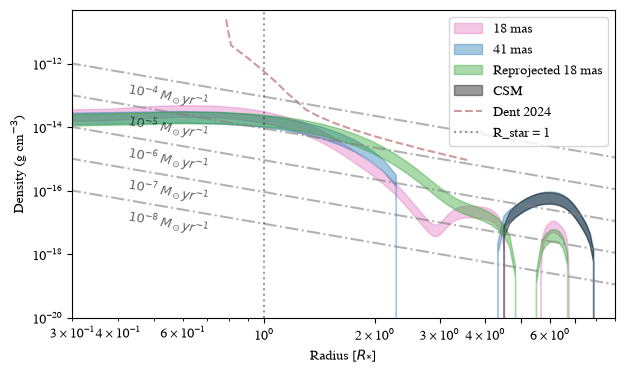

In [340]:
plot_1d_abel_massloss_bkg_rstar(abels,info3,radius3,ax_ymin=1e-20,ax_ymax=5e-11, xmin= 0.3,xmax=9,dent=True)

In [341]:
radius3['csm']['arc_1d'].value.shape

(198,)

Make a table for Jared

In [66]:
import pandas as pd

In [67]:
abels

{'hr': array([ 4.37626359e-17,  4.17789743e-17,  3.86491843e-17,  3.54910617e-17,
         3.66894810e-17,  4.14861670e-17,  4.54114205e-17,  4.74019105e-17,
         4.76580803e-17,  4.64032082e-17,  4.38996153e-17,  4.04408320e-17,
         3.63286013e-17,  3.18561207e-17,  2.72883137e-17,  2.28471461e-17,
         1.87084351e-17,  1.49935696e-17,  1.17736503e-17,  9.07182650e-18,
         6.87153436e-18,  5.13064800e-18,  3.78901105e-18,  2.77986832e-18,
         2.03588237e-18,  1.49484139e-18,  1.10385169e-18,  8.19931438e-19,
         6.11051458e-19,  4.54620965e-19,  3.35682071e-19,  2.44736236e-19,
         1.75572328e-19,  1.23897663e-19,  8.62601431e-20,  5.96328989e-20,
         4.12707689e-20,  2.87766895e-20,  2.02674774e-20,  1.44495770e-20,
         1.06286270e-20,  8.56273271e-21,  8.24735284e-21,  9.66849407e-21,
         1.26091612e-20,  1.65996351e-20,  2.09877312e-20,  2.51004930e-20,
         2.84271529e-20,  3.07243522e-20,  3.20211710e-20,  3.25399127e-20,
      

In [68]:
radius3['hr']['pc_1d']

<Quantity [2.44345866e-06, 4.07243110e-06, 5.70140353e-06, 7.33037597e-06,
           8.95934841e-06, 1.05883208e-05, 1.22172933e-05, 1.38462657e-05,
           1.54752382e-05, 1.71042106e-05, 1.87331830e-05, 2.03621555e-05,
           2.19911279e-05, 2.36201004e-05, 2.52490728e-05, 2.68780452e-05,
           2.85070177e-05, 3.01359901e-05, 3.17649625e-05, 3.33939350e-05,
           3.50229074e-05, 3.66518799e-05, 3.82808523e-05, 3.99098247e-05,
           4.15387972e-05, 4.31677696e-05, 4.47967421e-05, 4.64257145e-05,
           4.80546869e-05, 4.96836594e-05, 5.13126318e-05, 5.29416042e-05,
           5.45705767e-05, 5.61995491e-05, 5.78285216e-05, 5.94574940e-05,
           6.10864664e-05, 6.27154389e-05, 6.43444113e-05, 6.59733838e-05,
           6.76023562e-05, 6.92313286e-05, 7.08603011e-05, 7.24892735e-05,
           7.41182459e-05, 7.57472184e-05, 7.73761908e-05, 7.90051633e-05,
           8.06341357e-05, 8.22631081e-05, 8.38920806e-05, 8.55210530e-05,
           8.71500255e-05

In [69]:
data_jared_surface = pd.DataFrame({"HR surface density (g/cm2)": data_dens_1d3['hr'], "HR surf dens radius (pc)": radius3['hr']['pc_1d'],
        "LR surface density (g/cm2)": data_dens_1d3['lr'], "LR surface density radius (pc)": radius3['lr']['pc_1d'],
        "Reproj surface density (g/cm2)": data_dens_1d3['reproj'], "Reproj surf dens radius (pc)": radius3['reproj']['pc_1d'],
        "CSM surface density (g/cm2)": data_dens_1d3['csm'], "CSM Surf Dens Radius (pc)": radius3['csm']['pc_1d']})

In [70]:
data_jared_surface

,HR surface density (g/cm2),HR surf dens radius (pc),LR surface density (g/cm2),LR surface density radius (pc),Reproj surface density (g/cm2),Reproj surf dens radius (pc),CSM surface density (g/cm2),CSM Surf Dens Radius (pc)
0,0.009254,0.000002,0.007839,0.000006,0.007872,0.000006,-0.000033,0.000006
1,0.009169,0.000004,0.007527,0.000010,0.007619,0.000010,-0.000093,0.000010
2,0.009035,0.000006,0.007869,0.000014,0.008077,0.000014,-0.000209,0.000014
3,0.008844,0.000007,0.007534,0.000018,0.007891,0.000018,-0.000356,0.000018
4,0.008589,0.000009,0.006700,0.000022,0.007219,0.000022,-0.000519,0.000022
...,...,...,...,...,...,...,...,...
193,0.000002,0.000317,0.000055,0.000792,NaN,0.000792,0.000055,0.000792
194,0.000003,0.000318,0.000055,0.000796,NaN,0.000796,0.000055,0.000796
195,0.000003,0.000320,0.000054,0.000800,NaN,0.000800,0.000054,0.000800
196,0.000003,0.000322,0.000054,0.000804,NaN,0.000804,0.000054,0.000804


In [71]:
r_abel_pc['hr']

<Quantity [3.25794488e-06, 4.88691732e-06, 6.51588975e-06, 8.14486219e-06,
           9.77383463e-06, 1.14028071e-05, 1.30317795e-05, 1.46607519e-05,
           1.62897244e-05, 1.79186968e-05, 1.95476693e-05, 2.11766417e-05,
           2.28056141e-05, 2.44345866e-05, 2.60635590e-05, 2.76925315e-05,
           2.93215039e-05, 3.09504763e-05, 3.25794488e-05, 3.42084212e-05,
           3.58373936e-05, 3.74663661e-05, 3.90953385e-05, 4.07243110e-05,
           4.23532834e-05, 4.39822558e-05, 4.56112283e-05, 4.72402007e-05,
           4.88691732e-05, 5.04981456e-05, 5.21271180e-05, 5.37560905e-05,
           5.53850629e-05, 5.70140353e-05, 5.86430078e-05, 6.02719802e-05,
           6.19009527e-05, 6.35299251e-05, 6.51588975e-05, 6.67878700e-05,
           6.84168424e-05, 7.00458148e-05, 7.16747873e-05, 7.33037597e-05,
           7.49327322e-05, 7.65617046e-05, 7.81906770e-05, 7.98196495e-05,
           8.14486219e-05, 8.30775944e-05, 8.47065668e-05, 8.63355392e-05,
           8.79645117e-05

In [72]:
hr_lr_3d_dens = pd.DataFrame({"HR density (g/cm3)": abels['hr'], "HR density radius (pc)": r_abel_pc['hr'],
                            "LR density (g/cm3)": abels['lr'], "LR density radius (pc)": r_abel_pc['lr']})

In [73]:
reproj_csm_3d_dens = pd.DataFrame({ "Reproj density (g/cm3)": abels['reproj'], "Reproj Density Radius (pc)": r_abel_pc['reproj'],
                                    "CSM density (g/cm3)": abels['csm'], "CSM Density Radius (pc)": r_abel_pc['csm']})

ValueError: All arrays must be of the same length

In [ ]:
data_jared_surface.to_csv('saved_data/surface_1d.csv')

In [ ]:
hr_lr_3d_dens.to_csv('saved_data/hr_lr_1d_iat.csv')

In [ ]:
reproj_csm_3d_dens.to_csv('saved_data/reproj_csm_1d_iat.csv')